In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df=pd.read_csv("dataset_credit_TP3.csv")
df.head()


display(df.head())
print("Shape:", df.shape)


print("\nDataset information:")
df.info()

print("\nStatistical description:")
print(df.describe())



,id_client,age,revenu_annuel,anciennete_emploi,dette_totale,ratio_dette_revenu,nb_credits_en_cours,retards_paiement,revenu_stable,decision
0,1,25.0,88500.0,0.0,27400.0,0.31,2,0,Non,Refus
1,2,55.0,68500.0,24.0,9600.0,0.14,0,0,Non,Refus
2,3,50.0,61500.0,29.0,4700.0,0.08,5,0,Oui,Refus
3,4,40.0,42200.0,19.0,27000.0,NaN,1,0,Oui,Risque élevé
4,5,40.0,28200.0,15.0,11800.0,0.42,1,1,Oui,Risque élevé


Shape: (300, 10)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id_client            300 non-null    int64  
 1   age                  288 non-null    float64
 2   revenu_annuel        273 non-null    float64
 3   anciennete_emploi    278 non-null    float64
 4   dette_totale         300 non-null    float64
 5   ratio_dette_revenu   285 non-null    float64
 6   nb_credits_en_cours  300 non-null    int64  
 7   retards_paiement     300 non-null    int64  
 8   revenu_stable        280 non-null    str    
 9   decision             300 non-null    str    
dtypes: float64(5), int64(3), str(2)
memory usage: 27.8 KB

Statistical description:
        id_client         age  revenu_annuel  anciennete_emploi  dette_totale  \
count  300.000000  288.000000     273.000000         278.000000    300.000000   
mean   150.500000   

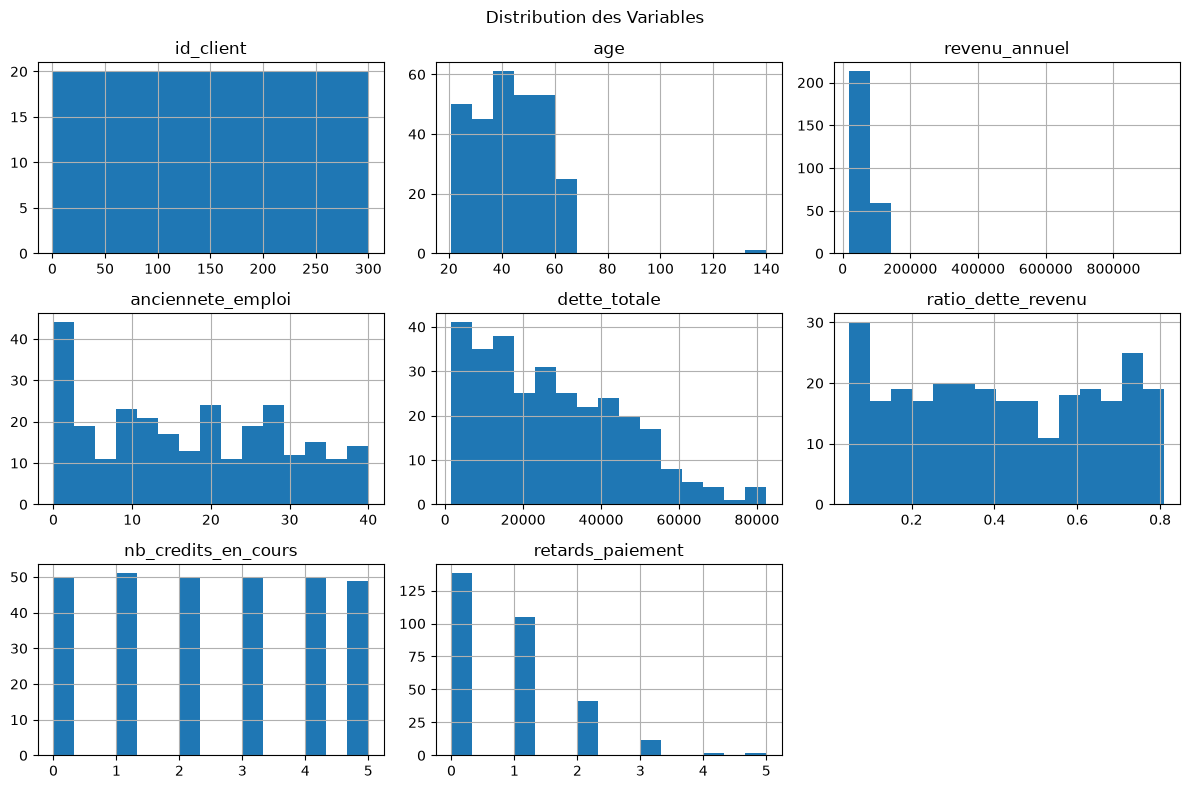

In [2]:
df.hist(figsize=(12, 8), bins=15)

plt.suptitle("Distribution des Variables")
plt.tight_layout()
plt.show()

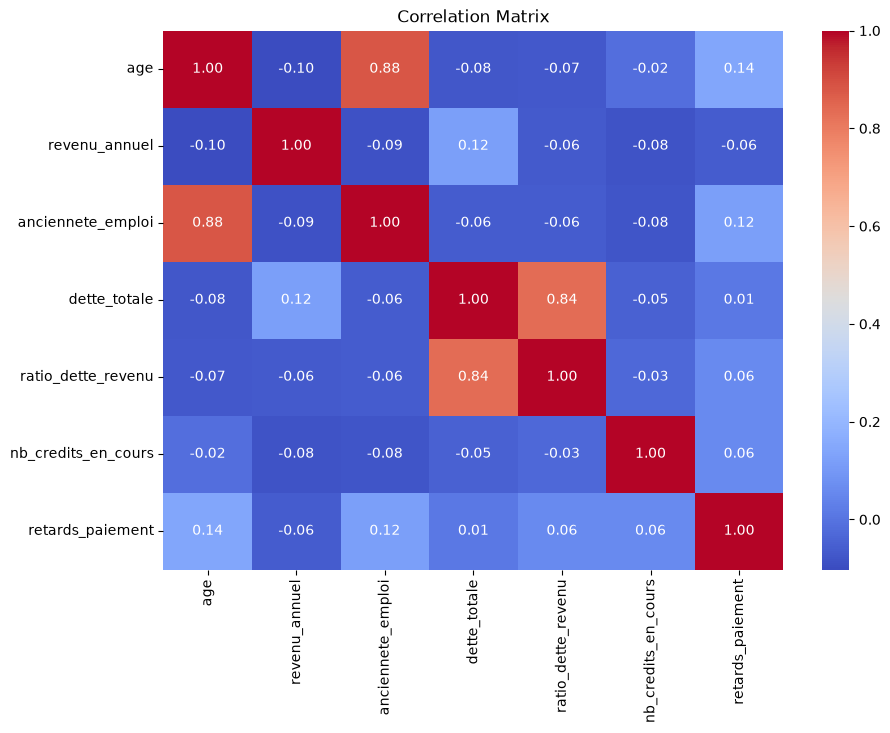

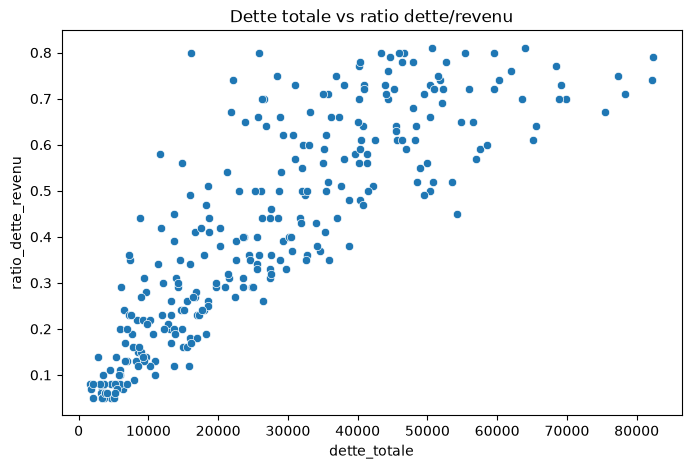

In [3]:

# Correlation matrix (excluding 'decision' ,'client id' and 'revenu_stable')
plt.figure(figsize=(10, 7))
sns.heatmap(
    df.drop(columns=["id_client", "decision", "revenu_stable"]).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Matrix")
plt.show()

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="dette_totale",
    y="ratio_dette_revenu"
)

plt.title("Dette totale vs ratio dette/revenu")
plt.show()

### Question 2: Quantitative vs. Qualitative Variables
* Identifier (to exclude from features):id_client (unique client ID number, no predictive meaning).
* Discrete quantitative variables: age (years), anciennete_emploi (employment tenure in years), nb_credits_en_cours (number of active loans), retards_paiement (number of past late payments).
* Continuous quantitative variables: revenu_annuel (annual income), dette_totale (total debt), ratio_dette_revenu (dette_totale / revenu_annuel).
* Qualitative variables: revenu_stable (binary categorical: Oui / Non) and decision (target variable with 3 nominal classes: Acceptation, Refus, Risque élevé).

* Justification: a variable is quantitative when its values are numbers on which arithmetic (mean, difference) makes sense, and qualitative when its values are labels or categories. Among the quantitative ones, discrete variables take countable integer values (years, counts), while continuous variables can take any value in a range (money amounts, and a ratio obtained by division). revenu_stable is binary (Oui/Non) and decision has 3 unordered classes, so both are nominal. id_client is only a unique label, so it carries no predictive information.

### Question 3: Target Distribution (decision) and Class Balance

In [4]:
counts = df['decision'].value_counts()
pcts = (df['decision'].value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({'Count': counts, 'Percentage (%)': pcts}))

,Count,Percentage (%)
decision,,
Risque élevé,146,48.67
Acceptation,108,36.00
Refus,46,15.33


The dataset is imbalanced: Risque élevé accounts for 48.67% (146 clients), Acceptation for 36.00% (108 clients), and Refus for only 15.33% (46 clients). Consequently, we must use stratified sampling (stratify=y) during the train/test split.

### Question 4: Descriptive Statistics for Quantitative Variables

In [5]:
quant_cols = [
    'age', 'revenu_annuel', 'anciennete_emploi', 'dette_totale',
    'ratio_dette_revenu', 'nb_credits_en_cours', 'retards_paiement'
]
stats = df[quant_cols].describe().T[['count', 'mean', '50%', 'std', 'min', 'max']]
stats = stats.rename(columns={'50%': 'median'})
display(stats)

,count,mean,median,std,min,max
age,288.0,43.319444,43.00,13.535939,21.00,140.00
revenu_annuel,273.0,67550.183150,63800.00,57683.860856,20000.00,950000.00
anciennete_emploi,278.0,17.212230,16.50,12.057396,0.00,40.00
dette_totale,300.0,27491.666667,25400.00,18295.699110,1600.00,82400.00
ratio_dette_revenu,285.0,0.420281,0.41,0.229847,0.05,0.81
nb_credits_en_cours,300.0,2.486667,2.00,1.706712,0.00,5.00
retards_paiement,300.0,0.803333,1.00,0.942133,0.00,5.00


## Missing Values, Outliers, and Encoding (Exercises 3.2 – 3.5)

### Question 5 (Exercise 3.2): Detecting Missing Values (`NaN`) and Bar Chart

,Missing Count,Missing (%)
revenu_annuel,27,9.00
anciennete_emploi,22,7.33
revenu_stable,20,6.67
ratio_dette_revenu,15,5.00
age,12,4.00


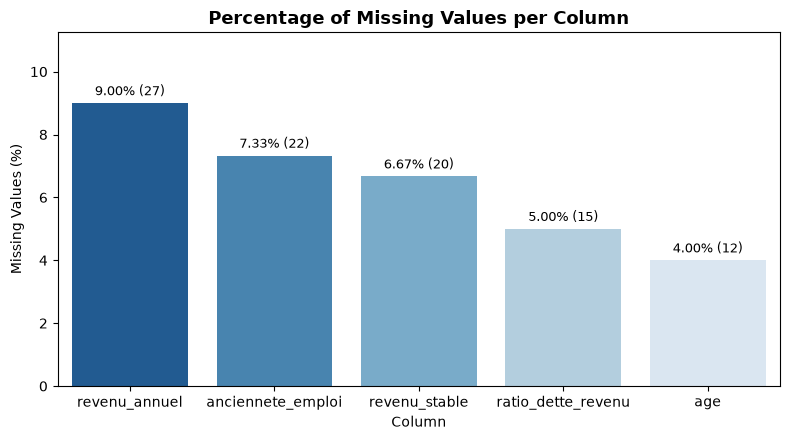

In [6]:
na_summary = pd.DataFrame({
    'Missing Count': df.isna().sum(),
    'Missing (%)': (df.isna().mean() * 100).round(2)
})
na_only = na_summary[na_summary['Missing Count'] > 0].sort_values('Missing (%)', ascending=False)
display(na_only)

plt.figure(figsize=(8, 4.5))
ax = sns.barplot(x=na_only.index, y=na_only['Missing (%)'], hue=na_only.index, palette='Blues_r', legend=False)
plt.title('Percentage of Missing Values per Column', fontsize=13, fontweight='bold')
plt.ylabel('Missing Values (%)')
plt.xlabel('Column')
plt.ylim(0, na_only['Missing (%)'].max() * 1.25)
for i, (pct, cnt) in enumerate(zip(na_only['Missing (%)'], na_only['Missing Count'])):
    ax.text(i, pct + 0.25, f'{pct:.2f}% ({cnt})', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

Q5 five columns contain missing values: revenu_annuel (9.00%, 27 rows), anciennete_emploi (7.33%, 22), revenu_stable (6.67%, 20), ratio_dette_revenu (5.00%, 15) and age (4.00%, 12). The other columns are complete. All five exceed 4%, so deleting rows with dropna() would lose a lot of data, so we impute instead.

In [7]:
quant_na_cols = ['age', 'revenu_annuel', 'anciennete_emploi', 'ratio_dette_revenu']
mean_med = pd.DataFrame({
    'Mean': df[quant_na_cols].mean(),
    'Median': df[quant_na_cols].median(),
    'Abs Diff': (df[quant_na_cols].mean() - df[quant_na_cols].median()).abs(),
    'Rel Diff (% of Median)': ((df[quant_na_cols].mean() - df[quant_na_cols].median()).abs() / df[quant_na_cols].median() * 100).round(2)
})
display(mean_med)

,Mean,Median,Abs Diff,Rel Diff (% of Median)
age,43.319444,43.00,0.319444,0.74
revenu_annuel,67550.183150,63800.00,3750.183150,5.88
anciennete_emploi,17.212230,16.50,0.712230,4.32
ratio_dette_revenu,0.420281,0.41,0.010281,2.51


### Question 6: Mean vs. Median

The mean and median are close for age (0.74% apart), ratio_dette_revenu (2.51%) and anciennete_emploi (4.32%), which suggests roughly symmetric distributions.

The largest gap is for revenu_annuel: mean 67,550 vs median 63,800 (about 5.9% of the median, or 3,750 in absolute terms). This signals a right-skewed distribution caused by extreme values, mainly the 950,000 income, which alone accounts for roughly 3,200 of that gap. The median is not affected by such values, so it is the safer choice for imputing this column.

In [8]:
mask_ratio_na = df['ratio_dette_revenu'].isna()
comparison_q8 = pd.DataFrame({
    'dette_totale': df.loc[mask_ratio_na, 'dette_totale'],
    'revenu_annuel': df.loc[mask_ratio_na, 'revenu_annuel'],
    'Median Fill': df['ratio_dette_revenu'].median(),
    'Exact Recalculation': (df.loc[mask_ratio_na, 'dette_totale'] / df.loc[mask_ratio_na, 'revenu_annuel']).round(4)
})
display(comparison_q8)

,dette_totale,revenu_annuel,Median Fill,Exact Recalculation
3,27000.0,42200.0,0.41,0.6398
20,36400.0,61600.0,0.41,0.5909
50,52500.0,64900.0,0.41,0.8089
53,14400.0,96000.0,0.41,0.1500
60,19400.0,45700.0,0.41,0.4245
67,46200.0,87100.0,0.41,0.5304
88,9500.0,20000.0,0.41,0.4750
99,50100.0,105400.0,0.41,0.4753
102,44100.0,NaN,0.41,NaN
105,3100.0,43300.0,0.41,0.0716


Question 7: Imputation strategy per column
We impute age with the median to stay robust against the 140 error in an otherwise symmetric distribution, and revenu_annuel with the median to avoid upward bias from right-skewed outliers like 950,000. For anciennete_emploi, the median is a safe, realistic default given its small 4.32% gap from the mean. ratio_dette_revenu is handled via exact recalculation (dette_totale / revenu_annuel, Q8), falling back to the median only for the 2 rows missing income, while the qualitative revenu_stable uses the mode. Outliers (age = 140, revenu_annuel = 950,000) are imputed in the same cell by first replacing them with NaN and then filling with the median.

### Question 8: Median imputation vs. exact recalculation of ratio_dette_revenu

Median imputation gives the same value (0.41) to all 15 missing rows, while the exact recalculation dette_totale / revenu_annuel gives each client his own ratio. The two differ a lot: client 50 has a true ratio of 0.81 (median fill: 0.41), and client 105 has 0.07.

**Exact recalculation is more reliable, because the ratio is a deterministic function of two columns we already have. The median would hide real information and push highly indebted clients toward the average. It works for 13 of the 15 rows. Rows 102 and 120 also miss revenu_annuel, so for those two we fall back to the median.

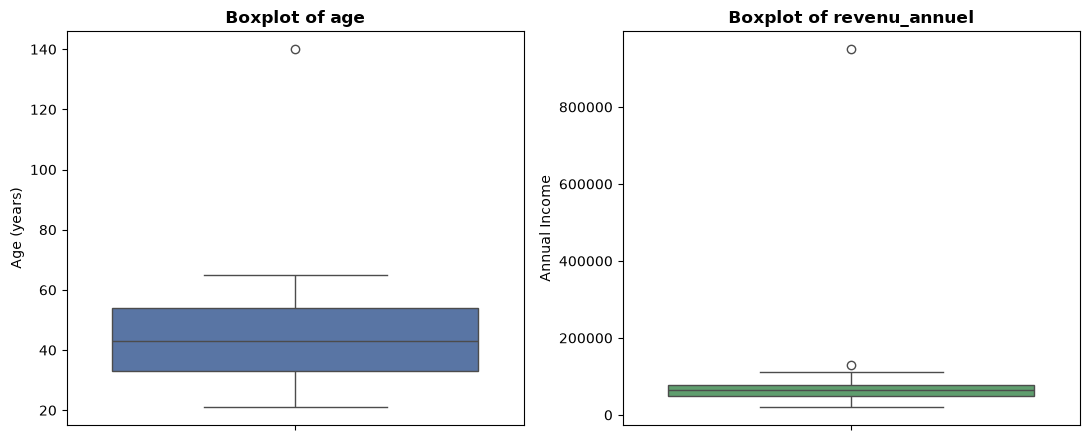

age: Q1=33.0, Q3=54.0, IQR=21.0, IQR bounds=[1.50, 85.50]
Outliers: [140.0] 

revenu_annuel: Q1=49700.0, Q3=78400.0, IQR=28700.0, IQR bounds=[6650.00, 121450.00]
Outliers: [950000.0, 128900.0] 

ratio_dette_revenu < 0: 0
age < 18: 0
age > 100: 1
anciennete_emploi > (age - 16): 0


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.boxplot(y=df['age'].dropna(), ax=axes[0], color='#4C72B0')
axes[0].set_title('Boxplot of age', fontweight='bold')
axes[0].set_ylabel('Age (years)')

sns.boxplot(y=df['revenu_annuel'].dropna(), ax=axes[1], color='#55A868')
axes[1].set_title('Boxplot of revenu_annuel', fontweight='bold')
axes[1].set_ylabel('Annual Income')
plt.tight_layout()
plt.show()

for col in ['age', 'revenu_annuel']:
    s = df[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    print(f'{col}: Q1={q1}, Q3={q3}, IQR={iqr}, IQR bounds=[{low:.2f}, {high:.2f}]')
    print('Outliers:', s[(s < low) | (s > high)].tolist(), '\n')

# Consistency checks (Question 10)
print('ratio_dette_revenu < 0:', (df['ratio_dette_revenu'] < 0).sum())
print('age < 18:', (df['age'] < 18).sum())
print('age > 100:', (df['age'] > 100).sum())
print('anciennete_emploi > (age - 16):', (df['anciennete_emploi'] > (df['age'] - 16)).sum())

### Questions 9-10: Outliers and consistency

**Outliers found (IQR rule):
- age: one value of 140, far above the upper bound (85.5) and biologically impossible. It is a data-entry error.
- revenu_annuel: 950,000, about 14 times the median, and 128,900, which is only just above the upper bound (121,450).

**Treatment: the age of 140 and the income of 950,000 are replaced by NaN and then imputed (see the cleaning cell below). The 128,900 income is kept: it is a plausible salary, and removing it would just discard real information about a high earner.

**Consistency checks: no negative ratio_dette_revenu, no client under 18, and no anciennete_emploi greater than age - 16. The only inconsistency is the single age above 100.

In [10]:
# Apply full cleaning and imputation pipeline
df_clean = df.copy()

# 1. Replace impossible/extreme outliers with NaN
df_clean.loc[df_clean['age'] > 100, 'age'] = np.nan
df_clean.loc[df_clean['revenu_annuel'] == 950000, 'revenu_annuel'] = np.nan

# 2. Recalculate ratio_dette_revenu where missing and components exist, then fallback to median
mask_recalc = df_clean['ratio_dette_revenu'].isna() & df_clean['dette_totale'].notna() & df_clean['revenu_annuel'].notna()
df_clean.loc[mask_recalc, 'ratio_dette_revenu'] = (
    df_clean.loc[mask_recalc, 'dette_totale'] / df_clean.loc[mask_recalc, 'revenu_annuel']
).round(4)
df_clean['ratio_dette_revenu'] = df_clean['ratio_dette_revenu'].fillna(df_clean['ratio_dette_revenu'].median())

# 3. Median imputation for remaining quantitative NaNs
for col in ['age', 'revenu_annuel', 'anciennete_emploi']:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# 4. Mode imputation for qualitative column revenu_stable
df_clean['revenu_stable'] = df_clean['revenu_stable'].fillna(df_clean['revenu_stable'].mode()[0])

print('Remaining missing values:', df_clean.isna().sum().sum())

Remaining missing values: 0


In [11]:
df_clean['revenu_stable_bin'] = df_clean['revenu_stable'].map({'Non': 0, 'Oui': 1})

feature_cols = [
    'age', 'revenu_annuel', 'anciennete_emploi', 'dette_totale',
    'ratio_dette_revenu', 'nb_credits_en_cours', 'retards_paiement', 'revenu_stable_bin'
]
X = df_clean[feature_cols]
y = df_clean['decision']

display(X.head())

,age,revenu_annuel,anciennete_emploi,dette_totale,ratio_dette_revenu,nb_credits_en_cours,retards_paiement,revenu_stable_bin
0,25.0,88500.0,0.0,27400.0,0.3100,2,0,0
1,55.0,68500.0,24.0,9600.0,0.1400,0,0,0
2,50.0,61500.0,29.0,4700.0,0.0800,5,0,1
3,40.0,42200.0,19.0,27000.0,0.6398,1,0,1
4,40.0,28200.0,15.0,11800.0,0.4200,1,1,1


### Question 11: Do decision trees need normalization?

**No.A tree only asks questions of the form "variable ≤ threshold?". Standardization or min-max scaling is a monotonic transformation: it does not change the order of the values, so the best splits stay the same, only the threshold value changes with the scale.

The perceptron and k-nearest neighbors are different: they use weighted sums or distances. Without scaling, revenu_annuel (tens of thousands) would dominate retards_paiement (0 to 5) and the model would be driven by units, not by information.

### Question 12: Encoding and X / y separation

revenu_stable is mapped to 0/1 (Non = 0, Oui = 1) in a new column revenu_stable_bin. X contains the 8 explanatory variables, without id_client (a simple identifier) and without the original text column revenu_stable. y is the target decision.

Train size: 210 | Test size: 90
|--- ratio_dette_revenu <= 0.41
|   |--- revenu_stable_bin <= 0.50
|   |   |--- class: Refus
|   |--- revenu_stable_bin >  0.50
|   |   |--- retards_paiement <= 4.00
|   |   |   |--- class: Acceptation
|   |   |--- retards_paiement >  4.00
|   |   |   |--- class: Refus
|--- ratio_dette_revenu >  0.41
|   |--- revenu_annuel <= 104650.00
|   |   |--- dette_totale <= 73600.00
|   |   |   |--- class: Risque élevé
|   |   |--- dette_totale >  73600.00
|   |   |   |--- class: Refus
|   |--- revenu_annuel >  104650.00
|   |   |--- age <= 29.00
|   |   |   |--- class: Refus
|   |   |--- age >  29.00
|   |   |   |--- class: Risque élevé



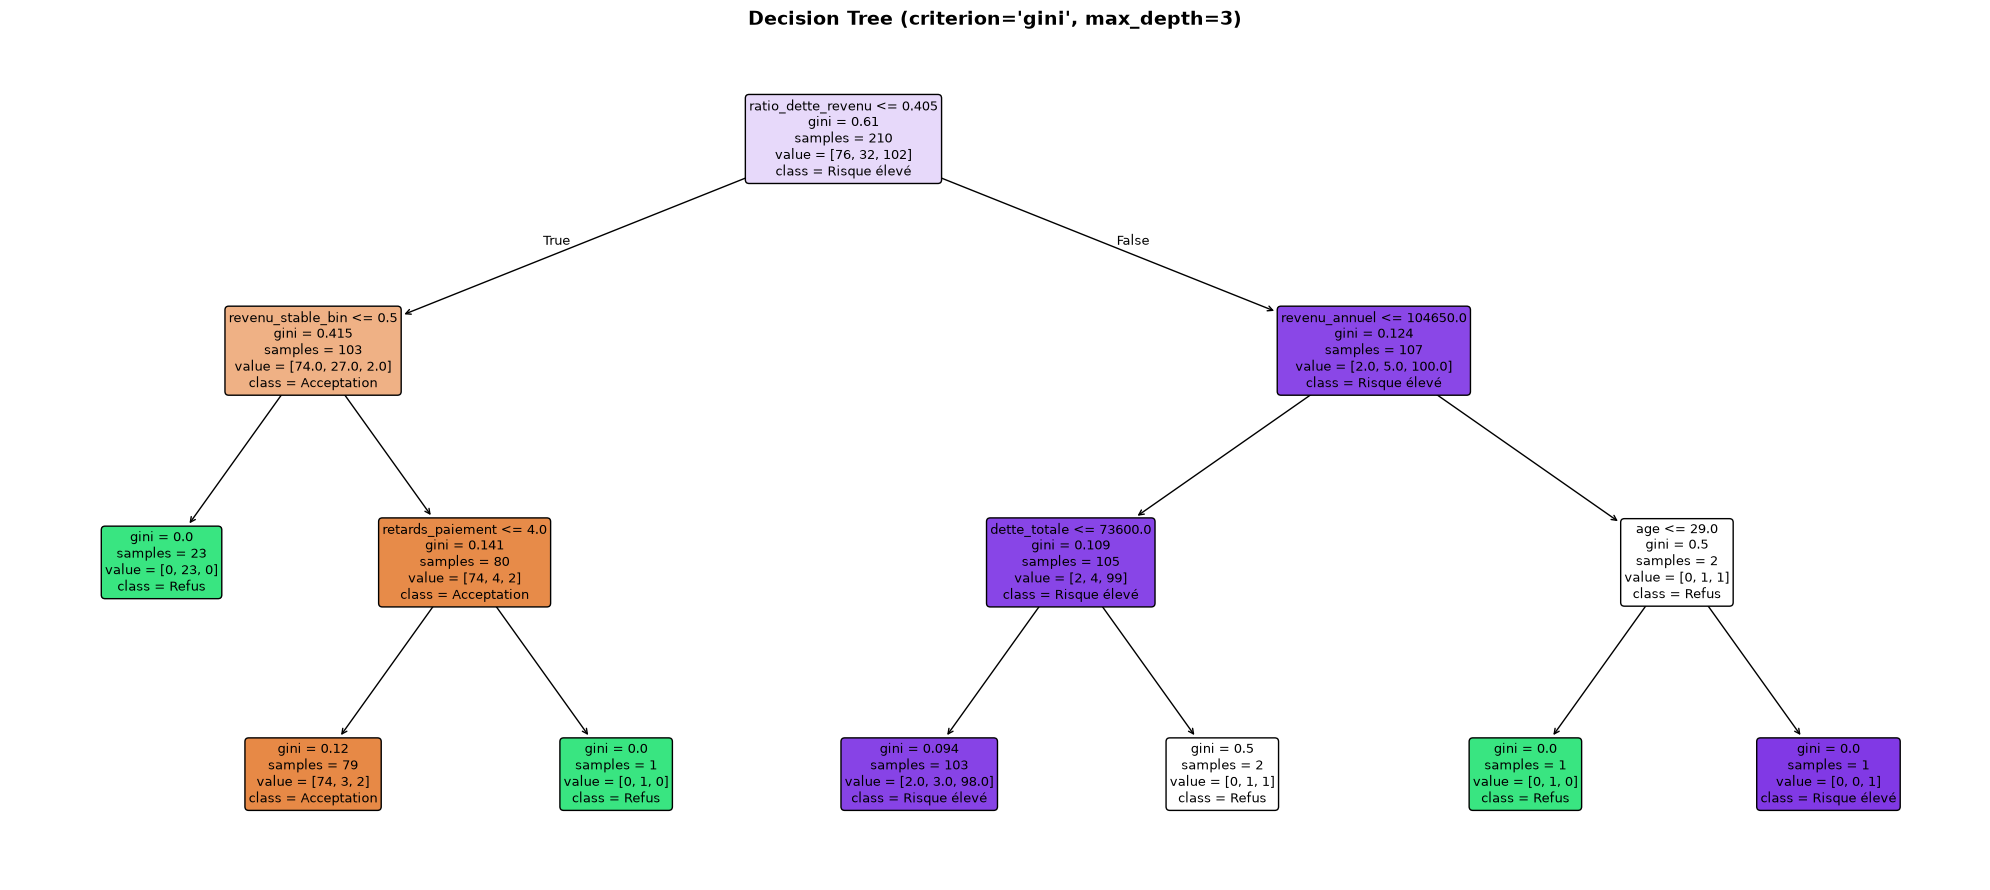

3 7 [210 103  23  80  79   1 107 105 103   2   2   1   1]


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)
print(f'Train size: {len(X_train)} | Test size: {len(X_test)}')

dt_gini = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
dt_gini.fit(X_train, y_train)

print(export_text(dt_gini, feature_names=feature_cols, class_names=dt_gini.classes_))

plt.figure(figsize=(20, 9))
plot_tree(
    dt_gini,
    feature_names=feature_cols,
    class_names=dt_gini.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree (criterion='gini', max_depth=3)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(dt_gini.get_depth(), dt_gini.get_n_leaves(), dt_gini.tree_.n_node_samples)

### Question 13-14: Train/test split and first tree

The data is split 70% training (210 clients) / 30% test (90 clients). stratify=y keeps the same proportions of Acceptation / Refus / Risque élevé in both sets, which matters because Refus is only 15% of the data. random_state=42 makes the split reproducible.

The tree uses criterion='gini' and max_depth=3: the depth limit keeps it readable and already limits overfitting.

Entropy tree -> Depth: 3, Leaves: 6
|--- ratio_dette_revenu <= 0.41
|   |--- revenu_stable_bin <= 0.50
|   |   |--- class: Refus
|   |--- revenu_stable_bin >  0.50
|   |   |--- ratio_dette_revenu <= 0.11
|   |   |   |--- class: Acceptation
|   |   |--- ratio_dette_revenu >  0.11
|   |   |   |--- class: Acceptation
|--- ratio_dette_revenu >  0.41
|   |--- age <= 45.50
|   |   |--- ratio_dette_revenu <= 0.57
|   |   |   |--- class: Risque élevé
|   |   |--- ratio_dette_revenu >  0.57
|   |   |   |--- class: Risque élevé
|   |--- age >  45.50
|   |   |--- class: Risque élevé



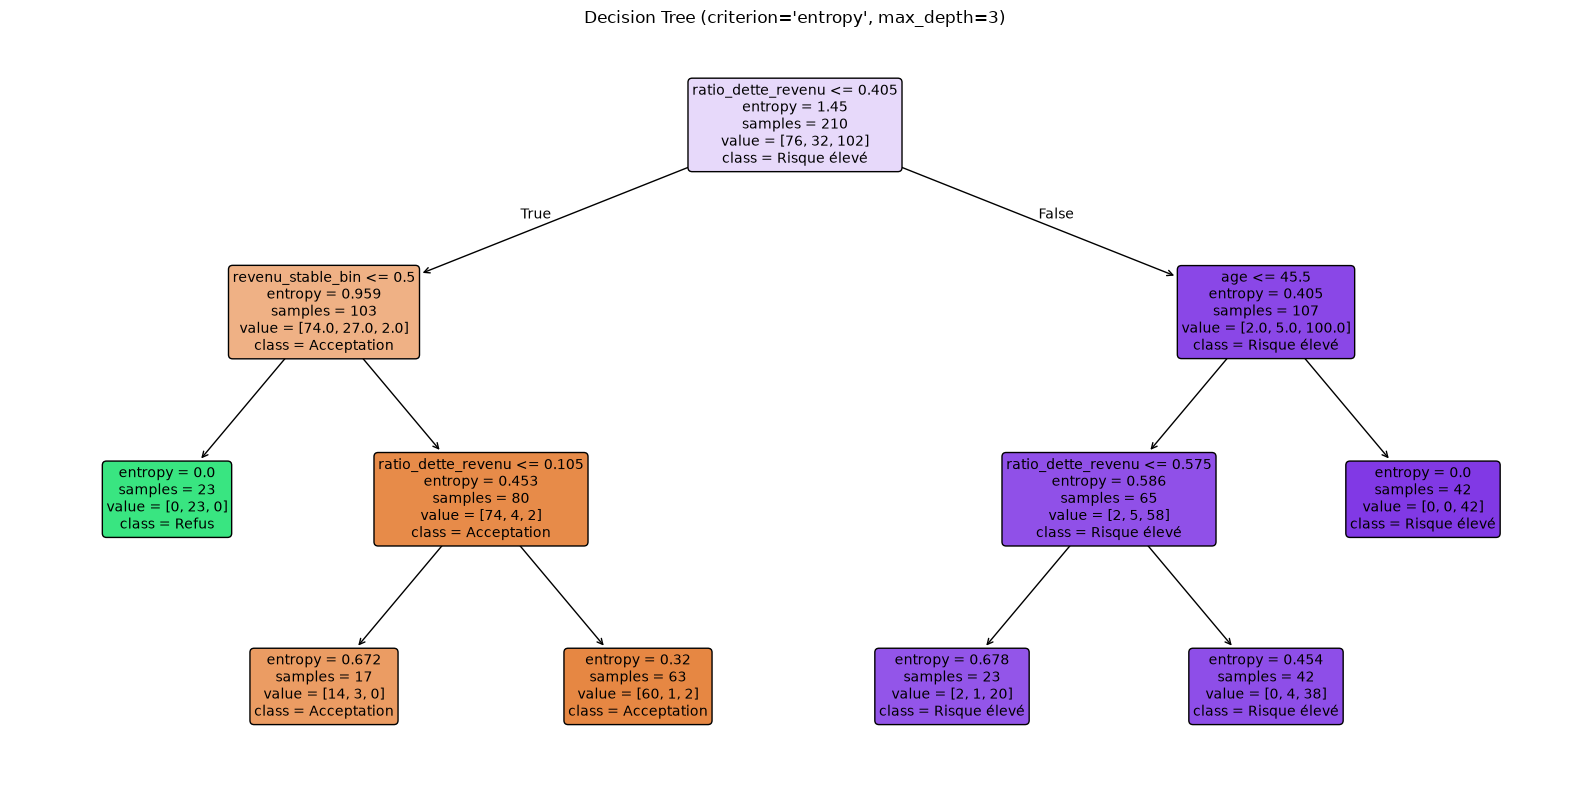

In [20]:
# Compare with criterion='entropy'
dt_entropy = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)
dt_entropy.fit(X_train, y_train)
print(f'Entropy tree -> Depth: {dt_entropy.get_depth()}, Leaves: {dt_entropy.get_n_leaves()}')
print(export_text(dt_entropy, feature_names=feature_cols, class_names=dt_entropy.classes_))

plt.figure(figsize=(16, 8))
plot_tree(
    dt_entropy,
    feature_names=feature_cols,
    class_names=[str(c) for c in dt_entropy.classes_],
    filled=True,
    rounded=True,
    fontsize=10,
)
plt.title("Decision Tree (criterion='entropy', max_depth=3)")
plt.tight_layout()
plt.show()


### Question 15: Anatomy of the Gini tree

- Root: ratio_dette_revenu ≤ 0.41, the first question, asked to all 210 training clients.
- Internal node:e.g. revenu_stable_bin ≤ 0.50 (a question on a variable that leads to further splits).
- Branch:one answer to a question, e.g. "ratio ≤ 0.41" (yes) or "ratio > 0.41" (no).
- Leaf: the end of a path, which gives the predicted class, e.g. class: Acceptation.
- Depth: 3. Number of leaves: 7.

### Question 16: Choice of the root and comparison with entropy

The tree tests every variable and every threshold, and keeps the split with the largest gain: the Gini impurity of the parent node minus the weighted average impurity of the two children. ratio_dette_revenu ≤ 0.41 wins because it separates the groups best: low ratio means mostly Acceptation/Refus, high ratio means mostly Risque élevé. The ratio sums up both debt and income in a single variable, which is why it beats dette_totale and revenu_annuel taken alone.

With criterion='entropy' the root is the same (ratio_dette_revenu ≤ 0.41), so both criteria agree on the main structure. The differences are only in the deeper splits: the entropy tree has depth 3 but only 6 leaves, and some of its splits (ratio ≤ 0.11, ratio ≤ 0.57) send both sides to the same class, so they make the groups purer without changing any prediction.

### Question 17: Decision rules

1. SI ratio_dette_revenu ≤ 0.41 ET revenu_stable = Non ALORS Refus
2. SI ratio_dette_revenu ≤ 0.41 ET revenu_stable = Oui ET retards_paiement ≤ 4 ALORS Acceptation
4. SI ratio_dette_revenu > 0.41 ET revenu_annuel ≤ 104650 ET dette_totale ≤ 73 600 ALORS Risque élevé
5. SI ratio_dette_revenu > 0.41 ET revenu_annuel > 104 650 ET age > 29 ALORS Risque élevé

note: rules such as retards_paiement > 4 --> Refus or age ≤ 29 -->Refus are probably based on very few clients, so they are less reliable than the main rules above.

In [14]:
new_client = pd.DataFrame([{
    'age': 35,
    'revenu_annuel': 55000,
    'anciennete_emploi': 6,
    'dette_totale': 55000 * 0.30,
    'ratio_dette_revenu': 0.30,
    'nb_credits_en_cours': 1,
    'retards_paiement': 0,
    'revenu_stable_bin': 1
}])[feature_cols]

print('Predicted decision:', dt_gini.predict(new_client)[0])
print('Class probabilities:', dict(zip(dt_gini.classes_, dt_gini.predict_proba(new_client)[0].round(4))))

Predicted decision: Acceptation
Class probabilities: {'Acceptation': np.float64(0.9367), 'Refus': np.float64(0.038), 'Risque élevé': np.float64(0.0253)}


### Question 18: Prediction for a new client

**Manual path in the Gini tree:
1. ratio_dette_revenu = 0.30 ≤ 0.41--> left branch
2. revenu_stable_bin = 1 > 0.50--> right branch
3. retards_paiement = 0 ≤ 4 --> leaf Acceptation

predict() returns the same class, with a probability of 0.937 for Acceptation. The statement does not give dette_totale, so it was set to 0.30 × 55 000 = 16500 to be consistent with the ratio. The path never uses that variable, so it doesn't affect the result.

In [15]:
y_train_pred = dt_gini.predict(X_train)
y_test_pred = dt_gini.predict(X_test)

print(f'Train Accuracy: {accuracy_score(y_train, y_train_pred):.4f}')
print(f'Test Accuracy:  {accuracy_score(y_test, y_test_pred):.4f}\n')

cm = confusion_matrix(y_test, y_test_pred, labels=dt_gini.classes_)
cm_df = pd.DataFrame(cm, index=[f'True: {c}' for c in dt_gini.classes_], columns=[f'Pred: {c}' for c in dt_gini.classes_])
display(cm_df)

print('\nClassification Report (Test):')
print(classification_report(y_test, y_test_pred, digits=4))

Train Accuracy: 0.9476
Test Accuracy:  0.9778



,Pred: Acceptation,Pred: Refus,Pred: Risque élevé
True: Acceptation,30,0,2
True: Refus,0,14,0
True: Risque élevé,0,0,44



Classification Report (Test):
              precision    recall  f1-score   support

 Acceptation     1.0000    0.9375    0.9677        32
       Refus     1.0000    1.0000    1.0000        14
Risque élevé     0.9565    1.0000    0.9778        44

    accuracy                         0.9778        90
   macro avg     0.9855    0.9792    0.9818        90
weighted avg     0.9787    0.9778    0.9777        90



### Question 19: Quality of the depth-3 tree

- **Accuracy: 0.948 on training, 0.978 on test.
- **Confusion matrix: the only errors are 2 Acceptation clients predicted as Risque élevé. All 14 Refus and all 44 Risque élevé clients are correctly classified.
- **Report: Refus has precision and recall of 1.00. Acceptation has precision 1.00 but recall 0.94 (2 of 32 missed). Risque élevé has recall 1.00 but precision 0.96, which is the same 2 errors seen from the other side.



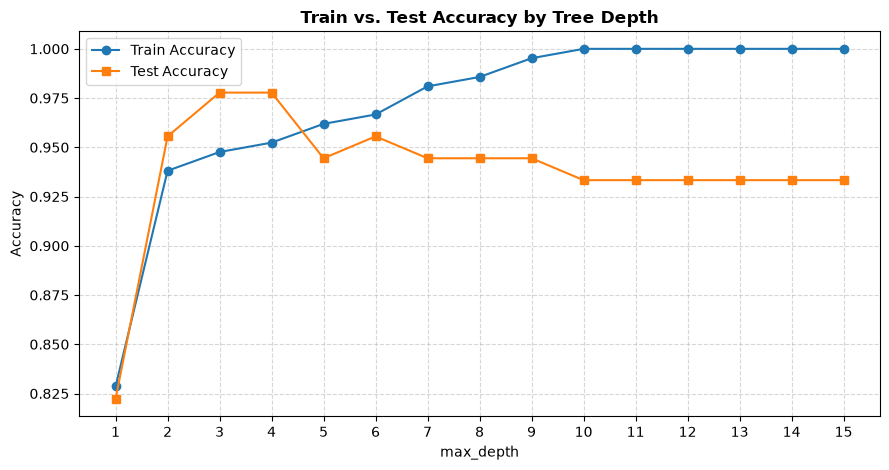

In [16]:
depths = range(1, 16)
train_accs, test_accs = [], []

for d in depths:
    clf = DecisionTreeClassifier(criterion='gini', max_depth=d, random_state=42)
    clf.fit(X_train, y_train)
    train_accs.append(accuracy_score(y_train, clf.predict(X_train)))
    test_accs.append(accuracy_score(y_test, clf.predict(X_test)))

plt.figure(figsize=(9, 4.8))
plt.plot(depths, train_accs, marker='o', label='Train Accuracy')
plt.plot(depths, test_accs, marker='s', label='Test Accuracy')
plt.xticks(list(depths))
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Train vs. Test Accuracy by Tree Depth', fontweight='bold')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Question 20: Overfitting

- **Depth 1: underfitting, both curves are low (about 0.82-0.83).
- **Depths 2-4: both curves are high and close. Test accuracy peaks at 0.978 for depths 3 and 4.
- **From depth 5: training accuracy keeps rising (0.96 to 1.00 at depth 10) while test accuracy drops to about 0.945, then 0.933 from depth 10 onward.

**Overfitting starts around depth 5, and is clear from depth 7 onward: the tree is memorizing training clients, reaching 100% training accuracy at depth 10 while test accuracy stays stuck below its peak. The best trade-off is depth 3-4, which is why max_depth=3 was a good choice.

In [17]:
fi_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': dt_gini.feature_importances_
}).sort_values('Importance', ascending=False)
display(fi_df)

,Feature,Importance
4,ratio_dette_revenu,0.667926
7,revenu_stable_bin,0.291111
6,retards_paiement,0.016502
0,age,0.009266
3,dette_totale,0.007742
1,revenu_annuel,0.007453
2,anciennete_emploi,0.000000
5,nb_credits_en_cours,0.000000


### Question 21: Variable importance

ratio_dette_revenu (0.67) and revenu_stable_bin (0.29) together carry about 96% of the importance. This is consistent with business intuition: a bank mainly looks at the debt burden relative to income, and at income stability.

revenu_annue and dette_totale score very low (about 0.007 each), not because they are unimportant, but because the ratio already combines both. anciennete_emploi and nb_credits_en_cours are never used by the depth-3 tree (importance 0).

One surprise: retards_paiement has only 0.017, although a history of late payments is normally a strong signal of credit risk. Likely explanation: the ratio and income stability already separate the classes well in this synthetic dataset, so late payments add little at depth 3.

In [18]:
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [2, 3, 4, 5, 6, 8, None],
    'min_samples_leaf': [1, 2, 3, 5, 10]
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

best_dt = grid_search.best_estimator_
print('Best Hyperparameters:', grid_search.best_params_)
print(f'Best 5-Fold CV Accuracy: {grid_search.best_score_:.4f}')
print(f'Best Model Train Accuracy: {accuracy_score(y_train, best_dt.predict(X_train)):.4f}')
print(f'Best Model Test Accuracy:  {accuracy_score(y_test, best_dt.predict(X_test)):.4f}')

Best Hyperparameters: {'criterion': 'gini', 'max_depth': 2, 'min_samples_leaf': 3}
Best 5-Fold CV Accuracy: 0.9381
Best Model Train Accuracy: 0.9381
Best Model Test Accuracy:  0.9778


### Question 22: Tuning the tree size

**Effect of the hyperparameters:
- max_depth caps the number of successive questions. A deeper tree has more leaves, fits the training set better and is more likely to overfit (Q20).
- min_samples_leaf forces every leaf to contain at least that many clients. It prevents tiny leaves built on 1-2 clients, so the tree gets smaller and more stable.
- Both reduce the tree size: higher bias, lower variance, usually better generalization when the tree was overfitting.

**GridSearchCV (5-fold CV on the training set, 70 combinations):
- Best parameters: criterion='gini', max_depth=2, min_samples_leaf=3.
- CV accuracy: 0.938. Train accuracy: 0.938. Test accuracy: 0.978.

This is a smaller tree than the depth-3 one from Q14, with the same test accuracy (0.978), so the extra depth bought nothing. The CV score (0.938) is the more honest estimate of future performance than the test score, because it averages 5 validation folds instead of relying on 90 clients. With only 210 training rows, several configurations probably tie within noise, so this is a good choice, not the single best one.

In [19]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

print(f'Random Forest Train Accuracy: {accuracy_score(y_train, rf.predict(X_train)):.4f}')
print(f'Random Forest Test Accuracy:  {accuracy_score(y_test, rf.predict(X_test)):.4f}\n')
print('Random Forest Classification Report (Test):')
print(classification_report(y_test, rf.predict(X_test), digits=4))

Random Forest Train Accuracy: 1.0000
Random Forest Test Accuracy:  0.9778

Random Forest Classification Report (Test):
              precision    recall  f1-score   support

 Acceptation     1.0000    0.9375    0.9677        32
       Refus     1.0000    1.0000    1.0000        14
Risque élevé     0.9565    1.0000    0.9778        44

    accuracy                         0.9778        90
   macro avg     0.9855    0.9792    0.9818        90
weighted avg     0.9787    0.9778    0.9777        90



### Question 23 (bonus): Random forest

The random forest (100 trees) gets 1.000 on training and .978 on test, with exactly the same classification report as the single tree: the same 2 Acceptation clients are misclassified.

A random forest builds many deep trees on bootstrap samples with random subsets of variables, then averages their votes. Each tree overfits on its own, but their errors differ, so averaging cancels much of that variance. That is why 100% training accuracy does not hurt the test score here.

On this split, the forest is not better than the single tree. One test client is worth about 1.1 points, so a 90-client test set can't separate the two models. The data is also very easy (the ratio and income stability almost solve it), so a single shallow tree already reaches the ceiling. The forest would matter more on a harder, noisier problem. Its trade-off is lower interpretability: we lose the readable IF/THEN rules.